# Iris: a multiclass workflow

The workflow of [California housing with pipelines](../california_with_pipelines.ipynb), on a classification problem with three classes: four kinds of model in pipelines, compared by cross-validation, the chosen one tested once. Nothing new is explained here; every step links to where it is. What the iris data adds is a lesson about small, easy datasets.

## The data

150 iris flowers of three species, 50 of each, with four measurements in centimetres: the length and width of the sepals and of the petals. How to explore a table like this one, step by step, is in [Exploring a dataset](../../../data-preparation/deep-dives/exploring_a_dataset.ipynb); here, only the essentials:

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X = iris.data
y = iris.target
X.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


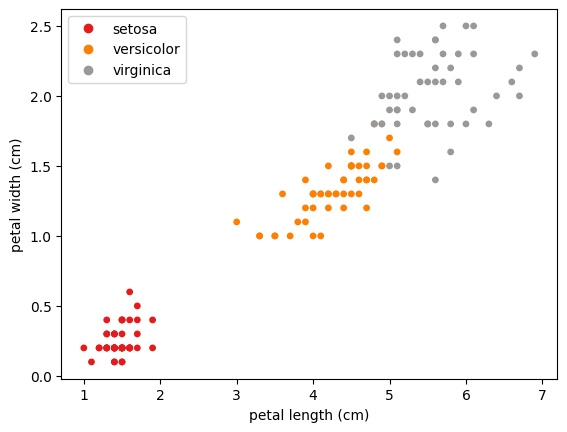

In [ ]:
import matplotlib.pyplot as plt

scatter = plt.scatter(X["petal length (cm)"], X["petal width (cm)"], c=y, cmap="Set1", s=15)
plt.legend(scatter.legend_elements()[0], iris.target_names)
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.show()

The petals alone almost separate the species: setosa stands apart, and versicolor and virginica overlap only at their border. This is an easy problem, which matters for how the results below should be read.

## Splitting

With 150 flowers, a three-way split would leave 30 for validation and 30 for testing, where a single flower is 3.3 percentage points of accuracy. So the test set is held back, stratified by species ([Overfitting and the train/test split](../../ml-fundamentals/overfitting_and_the_split.ipynb)), and the models are compared by cross-validation on the rest:

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
y_train.value_counts().sort_index().to_dict(), y_test.value_counts().sort_index().to_dict()

({0: 40, 1: 40, 2: 40}, {0: 10, 1: 10, 2: 10})

## Four classifiers

The scaler sits inside the pipeline of the two models that need it ([k-nearest neighbours](../../algorithms/neighbours/knn.ipynb#why-scaling-matters), and the penalty of [logistic regression](../../algorithms/linear-models/logistic_regression.ipynb)); the trees don't. `StratifiedKFold` keeps the three species in proportion in every fold:

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

candidates = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression()),
    "k-nearest neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "decision tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "random forest": RandomForestClassifier(random_state=42, n_jobs=-1),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = pd.DataFrame({name: cross_val_score(model, X_train, y_train, cv=folds) for name, model in candidates.items()})
scores.agg(["mean", "std", "min", "max"]).T.round(3)

,mean,std,min,max
logistic regression,0.958,0.029,0.917,1.0
k-nearest neighbours,0.958,0.029,0.917,1.0
decision tree,0.958,0.029,0.917,1.0
random forest,0.950,0.035,0.917,1.0


Three of the four are exactly tied, at 0.958 on average, and the forest is one flower behind. With 24 flowers in each validation fold, a single flower is about 4 points of accuracy, and the models mostly miss the same flowers, on the border between versicolor and virginica. The spread from one fold to another, from 0.92 to 1.0, is larger than any difference between the models. `idxmax` takes the first of the tied ones, logistic regression; any of the three would be just as justified.

## Testing once

In [ ]:
chosen_name = scores.mean().idxmax()
final_model = candidates[chosen_name].fit(X_train, y_train)
chosen_name, final_model.score(X_test, y_test)

('logistic regression', 0.9333333333333333)

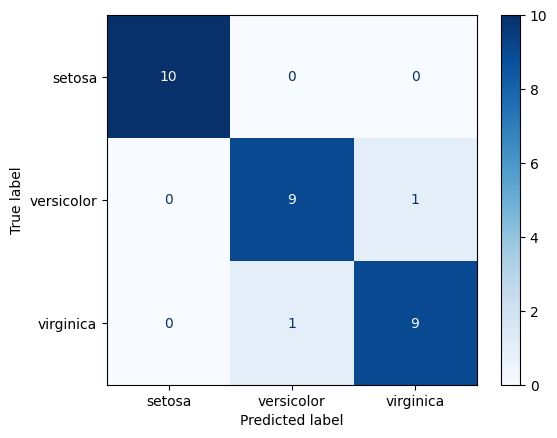

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test, display_labels=iris.target_names, cmap="Blues")
plt.show()

28 of the 30 test flowers are classified correctly: all ten setosas, and nine of each of the other two species, with one versicolor taken for a virginica and one virginica for a versicolor, the two species whose petals overlap. An accuracy of 0.93 here against 0.96 in cross-validation is a difference of one flower.

With three classes, the confusion matrix has a row and a column per species, and precision and recall are computed for each species in turn, as the positive class against the other two; the averages of the report summarise them ([Evaluating a classifier](../../evaluation/classification_metrics.ipynb)):

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, final_model.predict(X_test), target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## What iris can and can't teach

Iris is a good dataset to check that a workflow runs, and a poor one to compare models: almost any classifier separates three groups of flowers this distinct, and with 150 rows the differences between models are smaller than the uncertainty of measuring them. [Pima diabetes](../pima_diabetes.ipynb), with overlapping classes and missing values, and [A classifier in depth (MNIST)](../../evaluation/deep-dives/mnist_classifier_in_depth.ipynb), with ten classes and 70,000 images, are where the choice of model starts to matter.